In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)


All libraries imported successfully!
PyTorch version: 2.14.1+cpu


In [2]:
texts = [
    "I love this product",
    "This is amazing",
    "Very good quality",
    "I am happy with this",
    "Excellent experience",
    "The product is wonderful",
    "I really like it",
    "Fantastic service",
    "Very useful product",
    "I enjoyed using it",
    "This is terrible",
    "I hate this product",
    "Very poor quality",
    "I am disappointed",
    "Worst experience ever",
    "The product is awful",
    "I do not like it",
    "Terrible service",
    "Completely useless",
    "I regret buying this",
    "Amazing quality and service",
    "I am very satisfied",
    "The product works perfectly",
    "Really happy with the purchase",
    "I would recommend this",
    "Bad quality and poor service",
    "Not worth the money",
    "I am very unhappy",
    "The product stopped working",
    "I would not recommend this"
]

labels = [
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    1, 1, 1, 1, 1,
    0, 0, 0, 0, 0
]

df = pd.DataFrame({
    "text": texts,
    "label": labels
})

print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass counts:")
print(df["label"].value_counts())

                   text  label
0   I love this product      1
1       This is amazing      1
2     Very good quality      1
3  I am happy with this      1
4  Excellent experience      1

Dataset shape: (30, 2)

Class counts:
label
1    15
0    15
Name: count, dtype: int64


In [3]:
# Split data first to avoid data leakage
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

# Convert text into numerical features using TF-IDF
vectorizer = TfidfVectorizer(
    lowercase=True,
    max_features=1000,
    ngram_range=(1, 2)
)

X_train = vectorizer.fit_transform(X_train_text).toarray()
X_test = vectorizer.transform(X_test_text).toarray()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Text vectorization completed!")

Training shape: (24, 93)
Testing shape: (6, 93)
Text vectorization completed!


In [4]:
# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

print("PyTorch tensors created successfully!")

PyTorch tensors created successfully!


In [5]:
class SentimentClassifier(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)


model = SentimentClassifier(X_train_tensor.shape[1])

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print(model)

SentimentClassifier(
  (network): Sequential(
    (0): Linear(in_features=93, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Linear(in_features=8, out_features=1, bias=True)
  )
)


In [6]:
epochs = 100
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(epochs):
    # Training
    model.train()
    optimizer.zero_grad()

    train_logits = model(X_train_tensor)
    train_loss = criterion(train_logits, y_train_tensor)

    train_loss.backward()
    optimizer.step()

    # Evaluation
    model.eval()
    with torch.no_grad():
        train_probs = torch.sigmoid(model(X_train_tensor))
        val_logits = model(X_test_tensor)
        val_loss = criterion(val_logits, y_test_tensor)
        val_probs = torch.sigmoid(val_logits)

        train_preds = (train_probs >= 0.5).float()
        val_preds = (val_probs >= 0.5).float()

        train_acc = (
            train_preds.eq(y_train_tensor).float().mean().item()
        )
        val_acc = (
            val_preds.eq(y_test_tensor).float().mean().item()
        )

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

print("Training completed!")
print("Final training accuracy:", round(train_accuracies[-1], 3))
print("Final validation accuracy:", round(val_accuracies[-1], 3))

Training completed!
Final training accuracy: 1.0
Final validation accuracy: 0.0


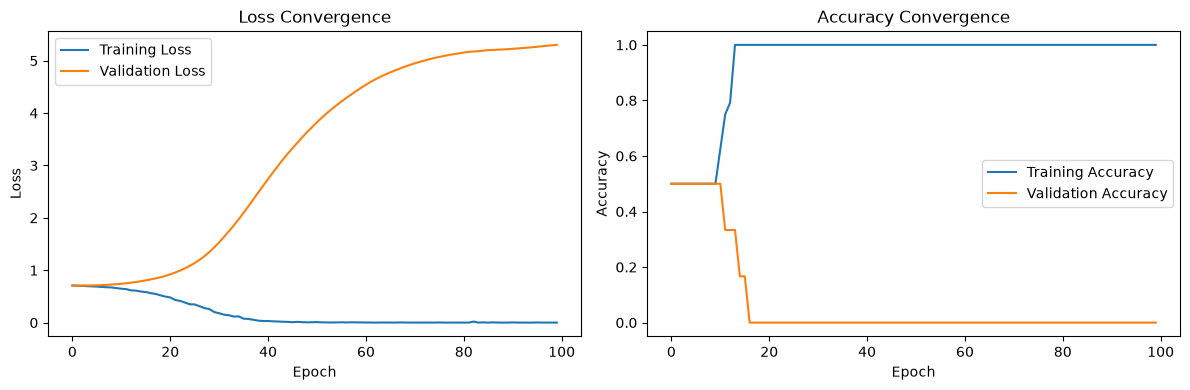

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_losses, label="Training Loss")
axes[0].plot(val_losses, label="Validation Loss")
axes[0].set_title("Loss Convergence")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(train_accuracies, label="Training Accuracy")
axes[1].plot(val_accuracies, label="Validation Accuracy")
axes[1].set_title("Accuracy Convergence")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [8]:
model.eval()

with torch.no_grad():
    test_logits = model(X_test_tensor)
    test_probs = torch.sigmoid(test_logits).numpy().ravel()
    test_preds = (test_probs >= 0.5).astype(int)

print("Test Accuracy:", accuracy_score(y_test, test_preds))
print(classification_report(
    y_test,
    test_preds,
    zero_division=0
))

Test Accuracy: 0.0
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       3.0
           1       0.00      0.00      0.00       3.0

    accuracy                           0.00       6.0
   macro avg       0.00      0.00      0.00       6.0
weighted avg       0.00      0.00      0.00       6.0



In [9]:
def predict_sentiment(text):
    model.eval()

    # Convert input text using the trained vectorizer
    text_vector = vectorizer.transform([text]).toarray()
    text_tensor = torch.tensor(text_vector, dtype=torch.float32)

    with torch.no_grad():
        probability = torch.sigmoid(model(text_tensor)).item()

    sentiment = "Positive" if probability >= 0.5 else "Negative"
    confidence = probability if probability >= 0.5 else 1 - probability

    return sentiment, confidence


# Try new sample reviews
samples = [
    "This product is excellent",
    "The quality is terrible"
]

for sample in samples:
    sentiment, confidence = predict_sentiment(sample)
    print("Review:", sample)
    print("Predicted sentiment:", sentiment)
    print("Model confidence:", round(confidence * 100, 2), "%")
    print("-" * 30)

Review: This product is excellent
Predicted sentiment: Positive
Model confidence: 96.8 %
------------------------------
Review: The quality is terrible
Predicted sentiment: Negative
Model confidence: 99.99 %
------------------------------


In [10]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

torch.save(
    model.state_dict(),
    "../models/sentiment_model.pth"
)

joblib.dump(
    vectorizer,
    "../models/tfidf_vectorizer.joblib"
)

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
